# BookPulse – Yapay Zekâ Destekli B2B Satış Zekâsı Platformu
2020 B2B kitap/kırtasiye satış verisi · 664.154 satır

In [2]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from bookpulse import config, data, portfolio as pf, next_calls as nc, customer_dna as cd, basket as mb, forecast as fc
from bookpulse.ui import tr_df as tr

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

In [3]:
import importlib, platform
print("Python", platform.python_version())
for pkg in ["streamlit", "pandas", "numpy", "scipy", "sklearn", "plotly", "openpyxl", "matplotlib", "ollama"]:
    try:
        mod = importlib.import_module(pkg)
        print(f"  ✓ {pkg:<11} {getattr(mod, '__version__', '')}")
    except ImportError:
        print(f"  ✗ {pkg:<11} kurulu değil -> pip install -r requirements.txt")

from bookpulse.advisor import ollama_status, setup_guide
durum = ollama_status()
print("\nOllama durumu:", {"ready": "hazır", "no_model": "çalışıyor, model yok", "not_running": "kurulu, çalışmıyor",
                         "not_installed": "bulunamadı"}[durum["step"]],
      "| adres:", durum["host"], "| modeller:", durum["models"] or "-")

Python 3.12.7
  ✓ streamlit   1.37.1
  ✓ pandas      2.2.2
  ✓ numpy       1.26.4
  ✓ scipy       1.13.1
  ✓ sklearn     1.5.1
  ✓ plotly      5.24.1
  ✓ openpyxl    3.1.5
  ✓ matplotlib  3.9.2
  ✓ ollama      

Ollama durumu: kurulu, çalışmıyor | adres: http://localhost:11434 | modeller: -


## 0 · Veri hazırlığı ve temizliği
Ham Excel okunur ve `data.clean()` ile temizlenir. Fonksiyon, her çıkarılan satır için **gerekçe** döndürür.

In [4]:
raw = data.load_raw()
df, report = data.clean(raw)
df = data._add_fast_keys(df)
pd.Series(report, name="değer").to_frame()

,değer
Ham satır,664154
Metne döndürülen ürün adı,917
Ana müşteriye bağlanan alt hesap satırı,22369
İşaretlenen tekrar satır,6213
Çıkarılan satırlar,"{'satış dışı belge türü': 561, 'sembolik birim..."
Net fiyatı birim fiyattan yüksek (işaretlendi),0
Temiz satır,663572
Müşteri,1132
Ürün,43571
Kategori,306


In [5]:
raw_t = raw.assign(DocType=raw["InvoiceNo"].str[:3], Disc=1 - raw["NetPrice"] / raw["UnitPrice"])
raw_t.groupby("DocType").agg(**{"Satır": ("DocType", "size"), "Fatura": ("InvoiceNo", "nunique"),
                             "Müşteri": ("CustomerID", "nunique"), "Medyan İskonto": ("Disc", "median"),
                             "Medyan Adet": ("Quantity", "median")}).rename_axis("Belge türü")

,Satır,Fatura,Müşteri,Medyan İskonto,Medyan Adet
Belge türü,,,,,
BAD,336333,28454,926,0.38,1.00
BSR,305060,17955,300,0.38,1.00
DPE,5447,493,134,0.40,2.00
DPF,16753,568,121,0.40,2.00
MUH,561,1,1,0.31,1.00


Temiz satır: 663,572 | Ciro (Adet×NetPrice): 29,569,159 TL | Fatura: 47,466 | Müşteri: 1,132 | Ürün: 43,571 | Ort. iskonto: %39.2


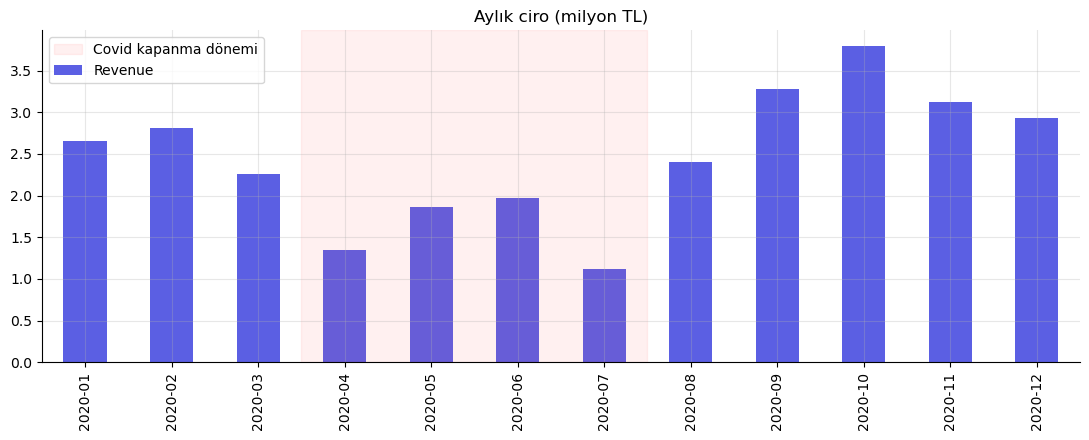

In [6]:
k = data.kpis(df)
print(f"Temiz satır: {len(df):,} | Ciro (Adet×NetPrice): {k['revenue']:,.0f} TL | Fatura: {k['invoices']:,} | "
      f"Müşteri: {k['customers']:,} | Ürün: {k['products']:,} | Ort. iskonto: %{100*k['avg_discount']:.1f}")

m = df.groupby("Month")["Revenue"].sum() / 1e6
ax = m.plot(kind="bar", color="#5B5FE3", title="Aylık ciro (milyon TL)")
ax.axvspan(2.5, 6.5, color="#FF4B4B", alpha=0.08, label="Covid kapanma dönemi")
ax.legend(); ax.set_xlabel(""); plt.tight_layout(); plt.show()

## 1 · Portföy DNA + Portföy Optimizasyonu
**DNA:** toplam adet (hacim) × aylık talep değişkenliği (CV). Eşikler, Yetersiz Satış Geçmişi dışındaki ürünlerin medyanı.
**Değişiklik:** CV artık ürünün ilk satış ayından itibaren hesaplanıyor. Takvim bazlı CV (`CV_Calendar`) karşılaştırma için tutuluyor.

In [7]:
portfolio, th = pf.build_portfolio(df)
print("Eşikler:", {k: round(v, 3) if isinstance(v, float) else v for k, v in th.items()})
tr(pf.dna_summary(portfolio))

Eşikler: {'volume_threshold': 29.0, 'cv_threshold': 1.034, 'limited_min_active_months': 3, 'limited_min_total_qty': 10}


,Ürün Sayısı,Adet,Ciro (₺),Ürün Payı %,Adet Payı %,Ciro Payı %
DNA,,,,,,
Çok Satan – Düzenli Talep,4572,"1,170,409.00","17,940,166.43",10.49,61.99,60.67
Çok Satan – Değişken Talep,2741,"483,462.00","7,791,053.84",6.29,25.60,26.35
Az Satan – Düzenli Talep,2708,"47,349.00","768,009.68",6.22,2.51,2.60
Az Satan – Değişken Talep,4538,"70,143.00","1,062,505.28",10.42,3.71,3.59
Yetersiz Satış Geçmişi,29012,"116,848.00","2,007,423.86",66.59,6.19,6.79


In [8]:
core = portfolio[portfolio["DNA"] != "Yetersiz Satış Geçmişi"]
old_volatile = core["CV_Calendar"] > th["cv_threshold"]
new_volatile = core["CV"] > th["cv_threshold"]
print(f"Takvim CV'sine göre 'değişken' görünüp aslında istikrarlı olan ürün: {(old_volatile & ~new_volatile).sum():,}")
print("Bu ürünlerin ilk satış ayları:")
core[old_volatile & ~new_volatile]["First_Month"].value_counts().sort_index().tail(8).rename_axis("İlk satış ayı").rename("Ürün sayısı").to_frame()

Takvim CV'sine göre 'değişken' görünüp aslında istikrarlı olan ürün: 1,197
Bu ürünlerin ilk satış ayları:


,Ürün sayısı
İlk satış ayı,
2020-03,151
2020-04,82
2020-05,94
2020-06,90
2020-07,52
2020-08,115
2020-09,213
2020-10,181


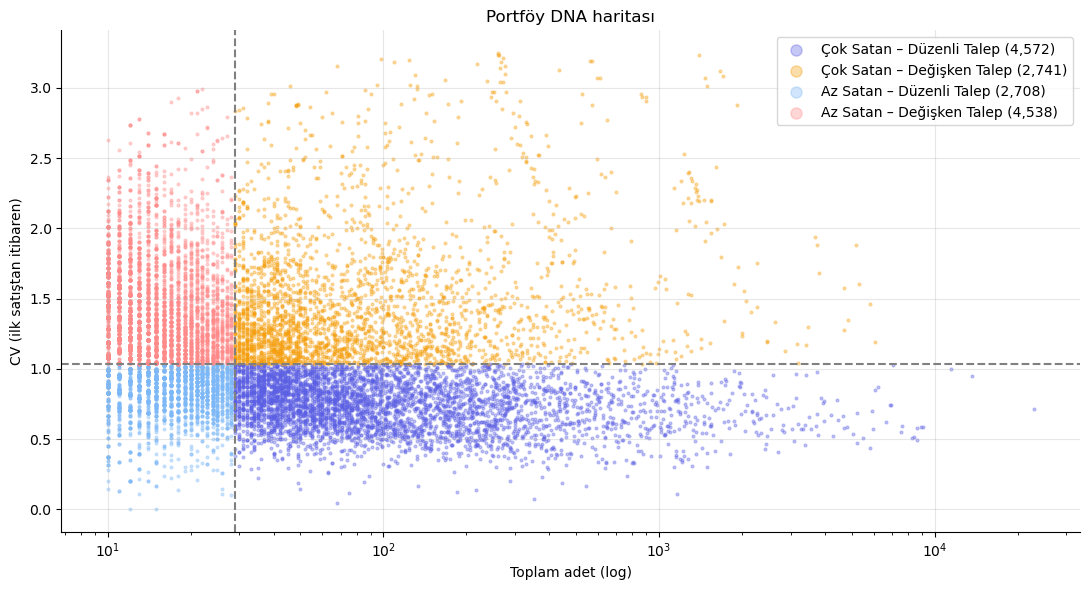

In [9]:
fig, ax = plt.subplots(figsize=(11, 6))
for dna in ["Çok Satan – Düzenli Talep", "Çok Satan – Değişken Talep", "Az Satan – Düzenli Talep", "Az Satan – Değişken Talep"]:
    d = core[core["DNA"] == dna]
    ax.scatter(d["Total_Qty"], d["CV"], s=4, alpha=0.35, label=f"{dna} ({len(d):,})", color=pf.DNA_COLORS[dna])
ax.axvline(th["volume_threshold"], ls="--", c="gray"); ax.axhline(th["cv_threshold"], ls="--", c="gray")
ax.set_xscale("log"); ax.set_xlabel("Toplam adet (log)"); ax.set_ylabel("CV (ilk satıştan itibaren)")
ax.set_title("Portföy DNA haritası"); ax.legend(markerscale=4); plt.tight_layout(); plt.show()

### Portföy Optimizasyonu – aksiyon önerileri
Her ürüne **performans puanı** (ciro %35, müşteri erişimi %20, trend %15, istikrar %15, düşük iskonto %15 – yüzdelik sıralar) ve
DNA + trend + yenilik kurallarıyla bir **aksiyon** atanır.

In [10]:
tr(pf.action_summary(portfolio))

,Ürün Sayısı,Ciro (₺),Ciro Payı %,Açıklama
Aksiyon,,,,
Sürekli Bulunurluğu Değerlendir,4191,"16,064,422.74",54.33,Sürekli ve yüksek talep: ürünün kesintisiz bul...
Sezon / Kampanya Planla,2741,"7,791,053.84",26.35,Yüksek ama dalgalı talep: zirve aylarından önc...
Stok Politikasını Gözden Geçir,16816,"2,091,395.73",7.07,Düşük ve öngörülemez talep: siparişe göre teda...
İzle (Düşüşte),381,"1,875,743.69",6.34,Güçlü ürün ama son dönemde düşüşte: nedenini a...
Hedefli Satış,2688,"765,295.79",2.59,Düşük ama düzenli talep: bu ürünü alan sadık m...
Yeni Ürün – İzle,6567,"525,335.49",1.78,Son 3 ayda satışa girdi: gelişimini takip et.
Ürün Performansını İncele,10119,"443,709.79",1.50,Çok düşük satış ve 90+ gündür hareketsiz: ürün...
Tanıtım Fırsatı,68,"12,202.02",0.04,Satışı yükselişte ama müşteri erişimi dar: gör...


In [11]:
cols = ["Description", "Category", "DNA", "Performance_Score", "Revenue", "Total_Qty", "Trend", "Customers"]
for act in ["Sürekli Bulunurluğu Değerlendir", "İzle (Düşüşte)", "Tanıtım Fırsatı", "Ürün Performansını İncele"]:
    print(f"\n=== {act}: {pf.ACTIONS[act]}")
    print(portfolio[portfolio["Action"] == act].sort_values("Revenue", ascending=False)[cols].head(5).pipe(tr).to_string())


=== Sürekli Bulunurluğu Değerlendir: Sürekli ve yüksek talep: ürünün kesintisiz bulunurluğu öncelikli değerlendirilmeli.
                                                                         Ürün           Kategori                        DNA  Performans Puanı   Ciro (₺)  Toplam Adet  Trend  Müşteri Sayısı
Ürün Kodu                                                                                                                                                                                   
9786058213241             Otuz Milyon Kelime - Çocuğunuzun Beynini Geliştirin       Aile - Çocuk  Çok Satan – Düzenli Talep             85.50 478,542.25    22,849.00   0.08             222
9786058422841                                                 Dedemin Bakkalı  Çocuk Öykü/Hikaye  Çok Satan – Düzenli Talep             97.10 201,214.90     9,101.00   1.67             409
9786056883569                                                    Abartma Tozu  Çocuk Öykü/Hikaye  Çok Satan – Düzenli Tale

In [12]:
tr(pf.category_concentration(portfolio, top=12))

,Ürün Sayısı,Ciro (₺),Çok Satan – Düzenli Ürün Sayısı,Yetersiz Satış Geçmişi %,HHI (yoğunlaşma),İlk %10 Ürünün Ciro Payı,Ciro Payı %
Kategori,,,,,,,
Roman/Öykü,2283,"3,676,929.70",455,42.40,81.00,79.10,12.40
Türkiye Roman,2917,"2,511,523.90",355,64.10,99.20,81.70,8.50
Çocuk Öykü/Hikaye,2817,"2,243,970.40",292,57.40,215.60,85.00,7.60
Dünya Roman,2377,"1,867,551.50",256,72.70,196.10,87.90,6.30
Polisiye,664,"1,312,019.30",111,62.30,254.90,86.40,4.40
Kişisel Gelişim,1084,"1,294,851.40",163,64.70,277.30,84.90,4.40
Korku Gerilim,393,"876,064.60",44,69.70,384.70,92.10,3.00
Temel Yeterlilik Testi - Alan Yeterlilik Testi (YKS-TYT/AYT),161,"867,921.70",33,22.40,452.50,71.30,2.90
Dünya Klasik,1201,"752,189.60",211,57.90,228.70,78.50,2.50


## 2 · Sıradaki 10 Arama v2

In [13]:
engine = nc.NextCallsEngine(df, portfolio)
top_star = portfolio[portfolio["DNA"] == "Çok Satan – Düzenli Talep"]["Revenue"].idxmax()
print("Ürün:", portfolio.loc[top_star, "Description"], "|", portfolio.loc[top_star, "Category"])
rec = engine.recommend(top_star, n=10)
tr(rec.drop(columns=["StockCode", "Product", "Reason"]))

Ürün: Otuz Milyon Kelime - Çocuğunuzun Beynini Geliştirin | Aile - Çocuk


,Müşteri,DNA,Puan,Kategori Adedi,Kategori Siparişi,Farklı Ürün,Benzerlik Puanı,Son Alımdan Beri (gün),Şehir,Uyuyan,Öncelik
0,A01913,Çok Satan – Düzenli Talep,97.40,138.00,46,38,10.55,0,Unknown,False,Takip Et
1,A02363,Çok Satan – Düzenli Talep,96.20,28.00,16,16,12.72,0,ISTANBUL,False,Teklif Sun
2,A00851,Çok Satan – Düzenli Talep,95.50,30.00,20,19,13.77,0,ISTANBUL,False,Hemen Ara
3,A02537,Çok Satan – Düzenli Talep,95.10,42.00,8,30,9.85,0,ISTANBUL,False,Takip Et
4,A01974,Çok Satan – Düzenli Talep,94.40,31.00,13,20,10.45,0,ISPARTA,False,Takip Et
5,A01652,Çok Satan – Düzenli Talep,94.20,22.00,7,14,14.34,0,ANTALYA,False,Hemen Ara
6,A02046,Çok Satan – Düzenli Talep,93.40,35.00,11,16,6.01,0,ANKARA,False,Takip Et
7,A00662,Çok Satan – Düzenli Talep,93.40,25.00,8,12,12.17,2,KAYSERI,False,Teklif Sun
8,A00595,Çok Satan – Düzenli Talep,93.20,21.00,9,11,12.68,1,ISTANBUL,False,Teklif Sun
9,A01030,Çok Satan – Düzenli Talep,93.20,23.00,8,8,9.86,1,BURSA,False,Takip Et


In [14]:
print("Örnek gerekçe →", rec.loc[0, "Reason"])

Örnek gerekçe → Bu müşteri bu ürünle birlikte alınan ürünleri satın almış, bu kategoride sık sipariş veriyor, ilgili kategoride yüksek alım hacmi; önerilen ürünü henüz satın almamış. Sürekli satan ürün: standart teklif sun.


In [15]:
v1 = engine.recommend(top_star, n=10, weights=nc.V1_WEIGHTS)
tr(v1[["CustomerID", "Score", "Category_Qty", "Category_Orders", "Days_Since_Last"]])

,Müşteri,Puan,Kategori Adedi,Kategori Siparişi,Son Alımdan Beri (gün)
0,A01913,99.70,138.00,46,0
1,A02610,98.10,102.00,30,0
2,A00928,98.00,200.00,23,1
3,P00970,97.70,101.00,9,6
4,P01233,97.50,30.00,19,1
5,A02046,97.40,35.00,11,0
6,A02363,97.00,28.00,16,0
7,A00851,96.80,30.00,20,0
8,A02093,96.40,48.00,5,2
9,A02533,96.20,21.00,13,1


### Çift yönlü geçiş: Portföy DNA → Sıradaki 10 Arama → Müşterinin Portföy DNA'sı → yeni ürün
Listeden bir müşteri seçildiğinde, o müşterinin **tüm alımlarının** ürün DNA gruplarına dağılımı şirket geneliyle karşılaştırılır.
Ardından müşterinin henüz almadığı ürünlerden biri seçilip yeniden Sıradaki 10 Arama listesi oluşturulabilir (panoda tek tıkla).

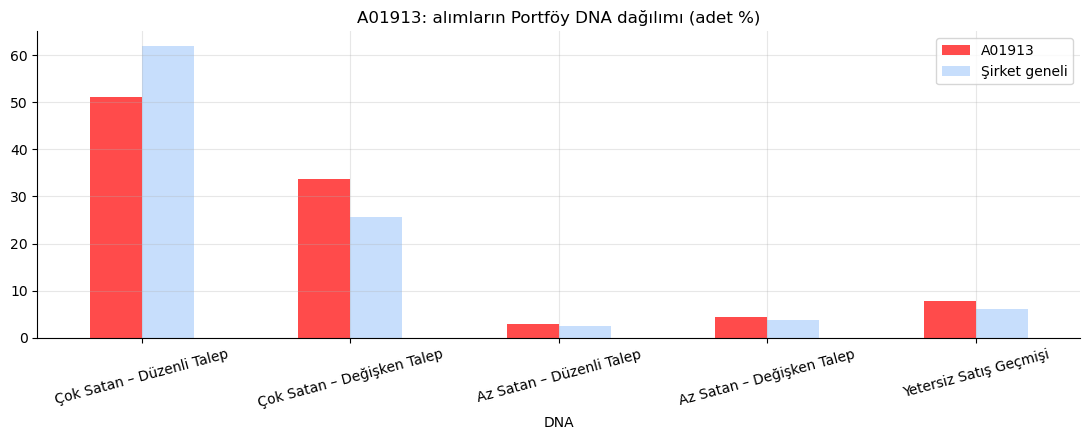

,Adet,Ciro (₺),Ürün Sayısı,Sipariş,Müşteri Payı %,Şirket Payı %,Fark (puan)
DNA,,,,,,,
Çok Satan – Düzenli Talep,"3,611.00","58,033.69",562,169,51.11,61.99,-10.87
Çok Satan – Değişken Talep,"2,385.00","41,679.77",210,146,33.76,25.60,8.15
Az Satan – Düzenli Talep,208.00,"3,350.35",124,86,2.94,2.51,0.44
Az Satan – Değişken Talep,314.00,"4,646.47",161,106,4.44,3.71,0.73
Yetersiz Satış Geçmişi,547.00,"9,793.22",365,126,7.74,6.19,1.55


In [16]:
musteri = rec.loc[0, "CustomerID"]
cp = engine.customer_portfolio(musteri)
ax = cp[["Customer_Share_%", "Company_Share_%"]].rename(
    columns={"Customer_Share_%": musteri, "Company_Share_%": "Şirket geneli"}).plot(
    kind="bar", color=["#FF4B4B", "#C7DEFC"], title=f"{musteri}: alımların Portföy DNA dağılımı (adet %)")
plt.xticks(rotation=15); plt.tight_layout(); plt.show()
tr(cp)

In [17]:
neden = engine.why_customer(musteri, top_star)
print(f"Kategori payı: %{neden['category_share_%']} | ürünle birlikte alınan ürünlerden {neden['n_similar_products_bought']} tanesini almış")
print("Örnekler:", ", ".join(neden["similar_products_bought"][:5]))
yeni_urun = engine.products_for_customer(musteri, n=1, dna_filter=None)["StockCode"].iloc[0]
print("\nYeni ürün:", engine.products.loc[yeni_urun, "Description"])
tr(engine.recommend(yeni_urun, n=5)[["CustomerID", "Score", "Priority", "Reason"]])

Kategori payı: %2.0 | ürünle birlikte alınan ürünlerden 19 tanesini almış
Örnekler: Vazgeçebilmek, Hayır Diyebilme Sanatı - Sınırların Kadar Özgürsün, Hiçbir Karşılaşma Tesadüf Değildir, Incognito  Beynin Gizli Hayatı, Bilinçaltının Gücü - Zihinsel ve Bedensel İyileşme

Yeni ürün: Ben Kazanmadan Bitmez


,Müşteri,Puan,Öncelik,Gerekçe
0,A01869,98.70,Teklif Sun,Bu müşteri bu ürünle birlikte alınan ürünleri ...
1,A01913,97.20,Takip Et,Bu müşteri bu ürünle birlikte alınan ürünleri ...
2,A01131,95.00,Takip Et,Bu müşteri bu ürünle birlikte alınan ürünleri ...
3,A00422,94.50,Teklif Sun,Bu müşteri bu ürünle birlikte alınan ürünleri ...
4,A00085,94.10,Takip Et,Bu müşteri bu ürünle birlikte alınan ürünleri ...


In [18]:
cust = df.groupby("CustomerID")["Revenue"].sum().idxmax()
print("Müşteri:", cust)
tr(engine.products_for_customer(cust, n=8))

Müşteri: A02348


,Ürün Kodu,Ürün,Kategori,DNA,Puan,Alan Benzer Müşteri,Kategori Yakınlığı,Gerekçe
0,9789755100982,Charlie'nin Çikolata Fabrikası,Roman/Öykü,Çok Satan – Düzenli Talep,97.40,38.00,0.07,Benzer 38 müşteri bu ürünü almış; müşterinin '...
1,9789755109428,Martıya Uçmayı Öğreten Kedi,Roman/Öykü,Çok Satan – Düzenli Talep,97.30,37.00,0.07,Benzer 37 müşteri bu ürünü almış; müşterinin '...
2,9786050822038,İçimdeki Müzik,Roman/Öykü,Çok Satan – Düzenli Talep,97.10,36.00,0.07,Benzer 36 müşteri bu ürünü almış; müşterinin '...
3,9789758440863,Kitaplardan Korkan Çocuk,Roman/Öykü,Çok Satan – Düzenli Talep,96.90,35.00,0.07,Benzer 35 müşteri bu ürünü almış; müşterinin '...
4,9786052993019,Momo,Roman/Öykü,Çok Satan – Düzenli Talep,96.90,35.00,0.07,Benzer 35 müşteri bu ürünü almış; müşterinin '...
5,9789754050929,Fadiş,Roman/Öykü,Çok Satan – Düzenli Talep,96.80,34.00,0.07,Benzer 34 müşteri bu ürünü almış; müşterinin '...
6,9789754050998,Dört Kardeştiler,Roman/Öykü,Çok Satan – Düzenli Talep,96.60,34.00,0.07,Benzer 34 müşteri bu ürünü almış; müşterinin '...
7,9786051736372,Yıktı Geçti! - Saftirik Greg'in Günlüğü 14,Roman/Öykü,Çok Satan – Değişken Talep,96.60,35.00,0.07,Benzer 35 müşteri bu ürünü almış; müşterinin '...


### Geriye dönük test
Ağırlıklar **Ocak–Haziran → Temmuz–Eylül** doğrulama penceresinde seçildi. Nihai başarı ayrı bir pencerede ölçülür:
model **Oca–Eyl** verisiyle kurulur, 300 rastgele Çok Satan – Düzenli Talep / Çok Satan – Değişken Talep ürünü için önerilen 10 müşterinin
ürünü **Eki–Ara**'da gerçekten alıp almadığına bakılır.

In [19]:
bt = nc.backtest(df, n_products=300)
tr(bt["table"])

,İsabet@10 %,En Az 1 İsabet %,İsabet Sayısı
Sıradaki 10 Arama v2,13.07,66.67,392
v1 (ekibin ilk modeli),10.43,63.67,313
Rastgele kategori müşterisi,2.13,17.67,64


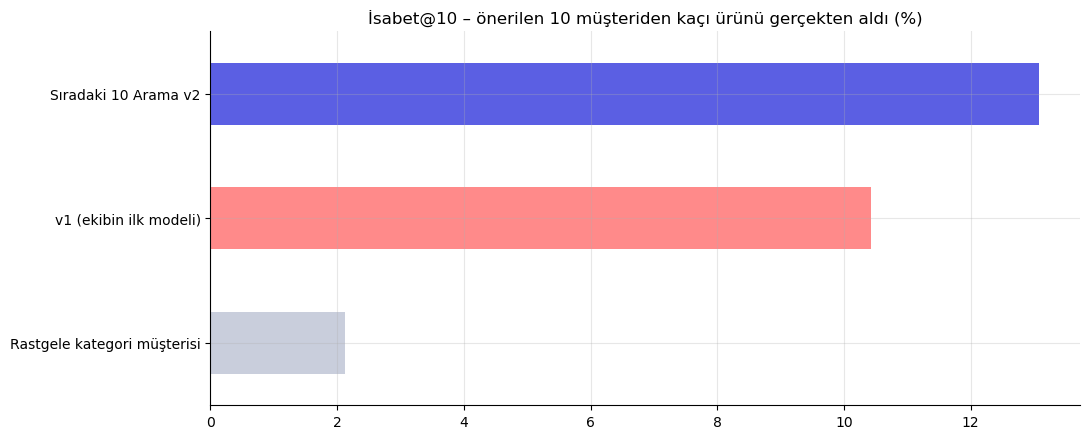

In [20]:
ax = bt["table"]["Precision@10_%"].plot(kind="barh", color=["#5B5FE3", "#FF8A8A", "#C9CEDC"],
                                        title="İsabet@10 – önerilen 10 müşteriden kaçı ürünü gerçekten aldı (%)")
ax.invert_yaxis(); plt.tight_layout(); plt.show()

## 3 · Müşteri DNA – RFM + K-Means
RFM skorları (1-5) ile iş dilinde segmentler; ayrıca log-ölçekli R/F/M + kategori çeşitliliği üzerinde K-Means (k silhouette ile).

In [21]:
rfm = cd.rfm_table(df)
customers, info = cd.kmeans_segments(rfm)
tr(cd.segment_summary(customers))

,Müşteri Sayısı,Ciro (₺),Medyan Son Alım (gün),Medyan Sipariş,Medyan Sipariş Tutarı,Müşteri Payı %,Ciro Payı %,Aksiyon
Segment,,,,,,,,
En Değerli Müşteriler,292,"21,609,791.40",2.00,88.00,473.20,25.80,73.10,En değerli ve aktif: yeni çıkanları ilk bunlar...
Sadık Müşteriler,140,"3,735,795.80",15.00,29.50,342.60,12.40,12.60,Düzenli alım: çapraz satış (Sepet Analizi) ve ...
Gelişen Müşteriler,146,"501,238.70",17.00,9.00,331.00,12.90,1.70,Yakın zamanda ve orta sıklıkta: sadakat progra...
Yeni Gözlenen Müşteriler,115,"386,052.40",11.00,2.00,292.10,10.20,1.30,Veride ilk kez 2020'nin son 90 gününde görüldü...
İlgi Gerektiren Müşteriler,6,"1,515.20",38.00,3.00,65.80,0.50,0.00,"Ortalama değerler, düşüş sinyali: kişiselleşti..."
Riskli Müşteriler,93,"1,815,560.40",116.00,13.00,496.80,8.20,6.10,"Eskiden sık alıyordu, uzun süredir yok: geri k..."
Riskli Değerli Müşteriler,13,"1,120,846.90",71.00,101.00,498.70,1.10,3.80,Yüksek ciro ama uzun süredir alım yok: yönetic...
Pasif Müşteriler,327,"398,358.20",247.00,2.00,242.80,28.90,1.30,Düşük değer ve uzun süredir pasif: düşük maliy...


In [22]:
print("Silhouette:", {k: round(v, 3) for k, v in info["silhouette"].items()}, "→ k =", info["best_k"])
tr(info["profile"])

Silhouette: {3: 0.375, 4: 0.321, 5: 0.314, 6: 0.296, 7: 0.296, 8: 0.269} → k = 3


,Müşteri Sayısı,Son Alım (gün),Sipariş Sayısı,Ciro (₺),Kategori Sayısı,Küme
Küme No,,,,,,
0,360,197.50,2.00,468.00,4.00,Düşük Değer · Pasif
1,408,25.00,11.00,"4,384.80",24.50,Orta Değer · Aktif
2,364,3.00,77.50,"37,617.40",74.50,Yüksek Değer · Aktif


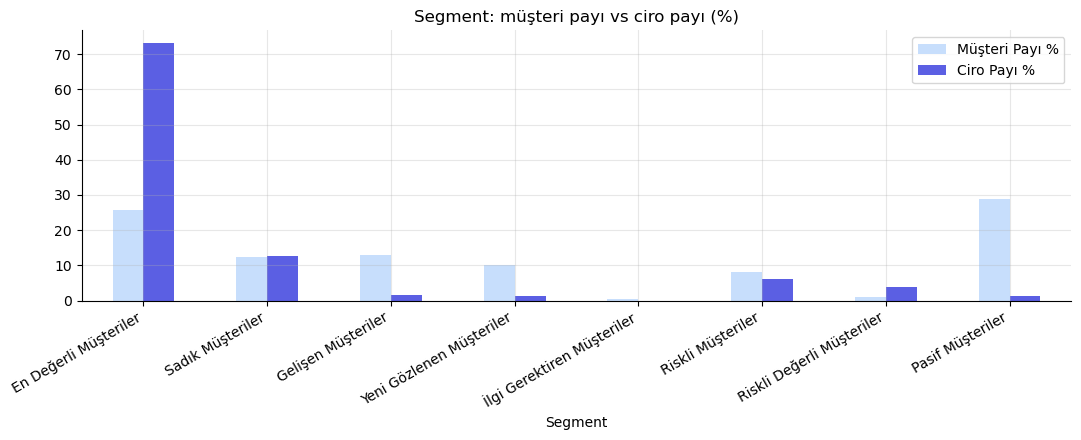

In [23]:
s = tr(cd.segment_summary(customers)[["Customer_Share_%", "Revenue_Share_%"]])
s.plot(kind="bar", title="Segment: müşteri payı vs ciro payı (%)", color=["#C7DEFC", "#5B5FE3"])
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

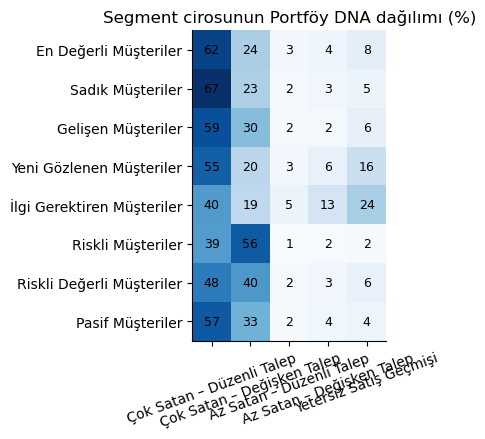

In [24]:
x = cd.segment_x_portfolio(df, customers, portfolio)
fig, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(x.values, cmap="Blues")
ax.set_xticks(range(len(x.columns)), x.columns, rotation=20); ax.set_yticks(range(len(x.index)), x.index)
for i in range(x.shape[0]):
    for j in range(x.shape[1]):
        ax.text(j, i, f"{x.values[i, j]:.0f}", ha="center", va="center", fontsize=9)
ax.set_title("Segment cirosunun Portföy DNA dağılımı (%)"); ax.grid(False); plt.tight_layout(); plt.show()

### Kaçan Sipariş Dedektörü
Her müşterinin siparişleri arasındaki tipik süre (medyan gün) hesaplanır; son siparişten bu yana geçen süre bunun en az
2 katıysa (ve en az 21 gün) müşteri işaretlenir. Geriye dönük kontrol: 30 Eylül itibarıyla işaretlenenlerin kaçı
Ekim–Aralık'ta yeniden sipariş verdi?

In [25]:
from bookpulse.ui import pct
mo = cd.missing_orders(df)
print(f"İşaretlenen müşteri: {len(mo)} · yıllık cirosu {mo['Revenue'].sum():,.0f} TL "
      f"(toplamın {pct(100 * mo['Revenue'].sum() / df['Revenue'].sum(), 1)})")
egitim, test_ = df[df["InvoiceDate"] <= "2020-09-30"], df[df["InvoiceDate"] > "2020-09-30"]
mo_eylul = cd.missing_orders(egitim)
geri = mo_eylul.index.isin(test_["CustomerID"].unique())
print(f"30 Eylül'de işaretlenen {len(mo_eylul)} müşterinin {pct(100 * geri.mean())} Ekim–Aralık'ta geri döndü, "
      f"{pct(100 * (1 - geri.mean()))} dönmedi.")
tr(mo.head(10))

İşaretlenen müşteri: 232 · yıllık cirosu 3,962,432 TL (toplamın %13,4'ü)
30 Eylül'de işaretlenen 135 müşterinin %41'i Ekim–Aralık'ta geri döndü, %59'u dönmedi.


,Sipariş Günü,Tipik Aralık (gün),Son Sipariş,Ciro (₺),Son Alımdan Beri (gün),Gecikme (kat),Beklenen Sipariş,Şehir
Müşteri,,,,,,,,
A00079,107,1.00,2020-11-26,"521,309.15",35,5.00,2020-11-27,ISTANBUL
A00284,123,1.00,2020-11-25,"512,666.24",36,5.10,2020-11-26,ADANA
A02346,28,1.00,2020-09-29,"406,215.78",93,13.30,2020-09-30,ANKARA
A02212,145,1.00,2020-07-21,"122,184.12",163,23.30,2020-07-22,ISTANBUL
A02391,86,2.00,2020-10-09,"106,167.00",83,11.90,2020-10-11,BALIKESIR
A00081,156,1.00,2020-11-10,"91,842.97",51,7.30,2020-11-11,ISTANBUL
A01218,86,2.00,2020-10-26,"88,149.46",66,9.40,2020-10-28,ERZURUM
A00722,52,1.00,2020-11-10,"84,284.85",51,7.30,2020-11-11,ISTANBUL
A02315,82,3.00,2020-11-27,"82,583.25",34,4.90,2020-11-30,ELAZIG


> **Bulgu:** *Riskli Müşteriler* müşterilerin cirosunun yarıdan fazlası **Çok Satan – Değişken Talep** ürünlerinden geliyor; yani bunlar
> büyük olasılıkla sezonluk (ör. okul dönemi) alıcılar. Geri kazanım aramaları sezon öncesine planlanmalı.

## 4 · Sepet Analizi
Sepet = fatura (2–150 kalem; çok büyük B2B faturaları sahte birliktelik ürettiği için dışarıda).
Apriori'nin 2'li kural adımı seyrek matris çarpımıyla hesaplanır. Metrikler: destek (support), güven (confidence), kaldıraç (lift).

In [26]:
rules = mb.association_rules(df, level="product")
print(f"{rules.attrs['n_baskets']:,} sepet, {len(rules):,} kural")
tr(rules[["A_Name", "B_Name", "Count_AB", "Support", "Confidence", "Lift"]].head(8))

42,463 sepet, 20,092 kural


,Ürün A,Ürün B,Birlikte Görülen Sepet,Destek,Güven,Kaldıraç (lift)
0,Dostluk Ormanı 8 - Gül Tomurcuk Nasıl Kaçtı?,Dostluk Ormanı 6 - İnci Dikenlisırtın Harika P...,21,0.00,0.84,"1,371.88"
1,Dostluk Ormanı 6 - İnci Dikenlisırtın Harika P...,Dostluk Ormanı 8 - Gül Tomurcuk Nasıl Kaçtı?,21,0.00,0.81,"1,371.88"
2,Dostluk Ormanı 10 - Nazlı Pofuduk'un Büyük Sür...,Dostluk Ormanı 8 - Gül Tomurcuk Nasıl Kaçtı?,21,0.00,0.78,"1,321.07"
3,Dostluk Ormanı 8 - Gül Tomurcuk Nasıl Kaçtı?,Dostluk Ormanı 10 - Nazlı Pofuduk'un Büyük Sür...,21,0.00,0.84,"1,321.07"
4,Dostluk Ormanı 6 - İnci Dikenlisırtın Harika P...,Dostluk Ormanı 9 Şeker Lezizkırıntıya Ne Oldu,21,0.00,0.81,"1,319.12"
5,Dostluk Ormanı 9 Şeker Lezizkırıntıya Ne Oldu,Dostluk Ormanı 6 - İnci Dikenlisırtın Harika P...,21,0.00,0.81,"1,319.12"
6,Dostluk Ormanı 8 - Gül Tomurcuk Nasıl Kaçtı?,Dostluk Ormanı 9 Şeker Lezizkırıntıya Ne Oldu,20,0.00,0.80,"1,306.55"
7,Dostluk Ormanı 9 Şeker Lezizkırıntıya Ne Oldu,Dostluk Ormanı 8 - Gül Tomurcuk Nasıl Kaçtı?,20,0.00,0.77,"1,306.55"


In [27]:
tr(mb.bundles(rules, n=10, min_confidence=0.15, cross_category_only=True)[["A_Name", "A_Category", "B_Name", "B_Category", "Confidence", "Lift"]])

,Ürün A,Kategori A,Ürün B,Kategori B,Güven,Kaldıraç (lift)
14,İlk Okuma Kitabım - Elif'in Bahar Bayramı,Eğitim Etkinlik Kitapları,İlk Okuma Kitabım - Elif Ata Binmeyi Öğreniyor,Çocuk Öykü/Hikaye,0.81,"1,116.11"
46,İnci Hastalandı İlk Okuma Kitabım,Eğitim Etkinlik Kitapları,İlk Okuma Kitabım - İnci Yabancılarla Gitmez,Masal & Hikaye Kitapları,0.87,997.96
68,İlk Okuma Kitabım - Elif'in İlk Harçlığı,Masal & Hikaye Kitapları,İlk Okuma Kitabım - Elif Ata Binmeyi Öğreniyor,Çocuk Öykü/Hikaye,0.69,944.67
76,İlk Okuma Kitabım - Elif Tatile Gidiyor,Masal & Hikaye Kitapları,İlk Okuma Kitabım - Elif Ata Binmeyi Öğreniyor,Çocuk Öykü/Hikaye,0.67,913.18
78,Editör 8. Sınıf VIP Türkçe Soru Bankası (Yeni),Türkçe,Editör 8. Sınıf VIP Matematik Soru Bankası (Yeni),LGS,0.70,900.73
100,İlk Okuma Kitabım - Elif Ata Binmeyi Öğreniyor,Çocuk Öykü/Hikaye,İlk Okuma Kitabım - Elif Uçağa Biniyor,Masal & Hikaye Kitapları,0.71,814.46
108,İlk Okuma Kitabım Elifin Doğum Günü,Roman/Öykü,İlk Okuma Kitabım - Elif Tatile Gidiyor,Masal & Hikaye Kitapları,0.56,798.45
152,İlk Okuma Kitabım Elif Bisiklete Binmeyi Öğren...,Eğitim Etkinlik Kitapları,İlk Okuma Kitabım - Elif Tatile Gidiyor,Masal & Hikaye Kitapları,0.53,744.96
164,İlk Okuma Kitabım - Elif Deniz’de Yatıya Kalıyor,Masal & Hikaye Kitapları,İlk Okuma Kitabım Elifin Doğum Günü,Roman/Öykü,0.67,725.86
170,İlk Okuma Kitabım - Elif Kayak Yapmayı Öğreniyor,Masal & Hikaye Kitapları,İlk Okuma Kitabım Elif Bisiklete Binmeyi Öğren...,Eğitim Etkinlik Kitapları,0.65,720.93


In [28]:
tr(mb.cross_sell(rules, top_star, n=8)[["B_Name", "B_Category", "Count_AB", "Confidence", "Lift"]])

,Ürün B,Kategori B,Birlikte Görülen Sepet,Güven,Kaldıraç (lift)
16228,Akış: Mutluluk Bilimi,Psikoloji Bilimi,43,0.06,9.51
19684,Bir Ömür Nasıl Yaşanır? - Hayatta Doğru Seçiml...,Kişisel Gelişim,48,0.07,2.37


In [29]:
cat_rules = mb.association_rules(df, level="category", min_support_count=50, min_lift=1.5)
tr(cat_rules[["A", "B", "Count_AB", "Confidence", "Lift"]].head(10))

,A,B,Birlikte Görülen Sepet,Güven,Kaldıraç (lift)
0,Kap Kağıtları,Masa Setleri,75,0.25,113.99
1,Masa Setleri,Kap Kağıtları,75,0.83,113.99
2,3000+ Parça Puzzle,2000 Parça Puzzle,79,0.57,105.70
3,2000 Parça Puzzle,3000+ Parça Puzzle,79,0.35,105.70
4,1500 Parça Puzzle,3000+ Parça Puzzle,60,0.28,84.44
5,3000+ Parça Puzzle,1500 Parça Puzzle,60,0.43,84.44
6,1500 Parça Puzzle,2000 Parça Puzzle,96,0.45,83.61
7,2000 Parça Puzzle,1500 Parça Puzzle,96,0.43,83.61
8,Sosyal Bilgiler,Türkçe,97,0.62,73.78
9,Türkçe,Sosyal Bilgiler,97,0.28,73.78


## 5 · Talep Tahmini
Veri yalnızca 2020'yi (≈51 hafta) kapsıyor ve Covid kırılmaları var → yıllık mevsimsellik öğrenilemez.
Bu yüzden ilk 20 kategori + toplam için **haftalık** seriler kurulur, dört yöntem son 8 haftada karşılaştırılır
ve **her seri için doğrulamada en iyi yöntem** seçilir.

In [30]:
S = fc.weekly_series(df, level="Category", top_n=20)
ev = fc.evaluate(S, test_weeks=8)
print("Kesim:", ev["cutoff"], "| GBM:", ev["gbm_name"])
ev["overall"].rename_axis("Yöntem")

Kesim: 2020-11-02 | GBM: HistGradientBoostingRegressor


,MAE,RMSE,MAPE_%,WAPE_%
Yöntem,,,,
Naive,577.52,"1,112.23",34.93,16.83
MA_4,489.79,918.29,32.63,14.27
SES,532.20,"1,033.42",51.56,15.51
GBM,985.33,"2,714.41",47.60,28.71
Seri bazında seçim,617.59,"1,121.92",39.01,18.00


In [31]:
ev["per_series"]["Best"].value_counts().rename_axis("En iyi yöntem").rename("Seri sayısı").to_frame()

,Seri sayısı
En iyi yöntem,
Naive,10
MA_4,5
GBM,4
SES,2


> **Dürüst sonuç:** Bu veri setinde gradient boosting, basit Naif/SES yöntemlerini **geçemiyor** (WAPE ≈ %25 vs %15).
> 2020'deki rejim değişiklikleri (kapanma → toparlanma → okul sezonu) karmaşık modelin öğrendiği örüntülerin
> test döneminde geçerli olmamasına yol açıyor. Daha uzun geçmiş (2019, 2021) eklendiğinde XGBoost/Prophet yeniden denenmeli.
> Ürün bazında haftalık talep çok gürültülü (WAPE > %70); ürün düzeyinde tahmin yerine **satış hızı** göstergesi önerilir.

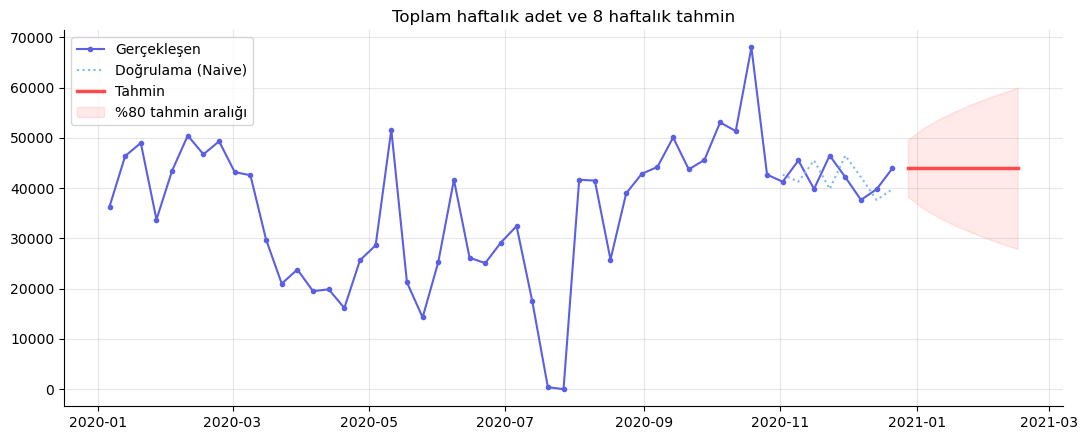

In [32]:
F = fc.forecast(S, horizon=8, evaluation=ev)
s = "TOPLAM"
f = F[F["Series"] == s]
fig, ax = plt.subplots()
ax.plot(S.index, S[s], marker="o", ms=3, color="#5B5FE3", label="Gerçekleşen")
best = ev["per_series"].loc[s, "Best"]
ax.plot(ev["preds"][best].index, ev["preds"][best][s], ls=":", color="#7CB8F7", label=f"Doğrulama ({best})")
ax.plot(f["Week"], f["Forecast"], lw=2.5, color="#FF4B4B", label="Tahmin")
ax.fill_between(f["Week"], f["Lower"], f["Upper"], color="#FF4B4B", alpha=0.12, label="%80 tahmin aralığı")
ax.set_title("Toplam haftalık adet ve 8 haftalık tahmin"); ax.legend(); plt.tight_layout(); plt.show()

In [33]:
tr(fc.outlook(S, F, weeks=4).head(10))

,Son 4 Hafta,Tahmin,Yöntem,Değişim %
TOPLAM,"163,595.00","175,744.00",Naive,7.40
Roman/Öykü,"23,634.00","23,820.00",Naive,0.80
Çocuk Öykü/Hikaye,"14,868.00","16,868.00",Naive,13.50
Türkiye Roman,"15,303.00","14,100.00",Naive,-7.90
Dünya Roman,"14,646.00","13,728.00",Naive,-6.30
Dünya Klasik,"6,718.00","8,184.00",Naive,21.80
Kişisel Gelişim,"6,178.00","6,660.00",Naive,7.80
Sözlük,"1,913.00","6,004.00",Naive,213.90
Türk Klasik,"5,589.00","5,288.00",Naive,-5.40
Polisiye,"2,994.00","4,792.00",Naive,60.10


## 6 · Yapay Zekâ Satış Danışmanı (Ollama)
Danışman, dil modelini bilgisayarınızda çalıştıran ücretsiz **Ollama** ile çalışır. Model ham veriye serbestçe erişmez;
yalnızca aşağıdaki **kontrollü analiz fonksiyonlarını** (araç) çağırabilir, bu yüzden cevaplardaki sayılar gerçek analiz
sonuçlarından gelir. Ollama bulunamazsa kurulum adımları gösterilir.

In [34]:
from bookpulse.advisor import TOOLS, SalesAdvisor, ping
from bookpulse.engine import BookPulse
from IPython.display import Markdown, display

pd.DataFrame([(t["name"], t["description"]) for t in TOOLS], columns=["araç", "açıklama"])

,araç,açıklama
0,get_kpis,"Genel satış özeti: ciro, adet, fatura, müşteri..."
1,top_entities,En iyi müşteri / ürün / kategori / şehirleri c...
2,category_trend,Son N ayı önceki N ayla karşılaştırarak satışl...
3,monthly_sales,Aylık ciro ve adet zaman serisi; opsiyonel ola...
4,portfolio_products,Portföy DNA / optimizasyon tablosundan ürün li...
5,portfolio_summary,DNA gruplarının ve önerilen aksiyonların ürün ...
6,search_product,Ürün adında arama yapar ve StockCode döndürür....
7,next_calls_for_product,Bir ürün için aranması gereken en uygun müşter...
8,top_call_list,Tüm Çok Satan – Düzenli Talep ve Çok Satan – D...
9,products_for_customer,Bir müşteriye önerilecek ürünler (benzer müşte...


In [35]:
durum = ollama_status()
if durum["step"] == "ready":
    print(f"Ollama hazır · model: {durum['model']} · kurulu modeller: {durum['models']}")
    print("Bağlantı testi (araçsız tek mesaj):", ping(durum["host"], "", durum["model"]))
else:
    display(Markdown(setup_guide(durum)))

**Ollama kurulu ama çalışmıyor.** Ollama uygulamasını açın (veya terminalde `ollama serve` çalıştırın), ardından aşağıdaki **Tekrar kontrol et** düğmesine basın.

1. **Ollama'yı indirin ve kurun:** https://ollama.com/download
   - macOS / Windows: indirilen kurulum dosyasını açın.
   - Linux: `curl -fsSL https://ollama.com/install.sh | sh`
2. **Ollama'yı başlatın:** uygulamayı açın (arka planda çalışır). Kontrol için terminalde `ollama --version`.
3. **Modeli indirin** (bir kez, ~4,7 GB; en az 8 GB RAM önerilir):
   ```
   ollama pull qwen2.5:7b
   ```
4. **Python paketlerini kurun** (Ollama'nın Python istemcisi dahildir):
   ```
   pip install -r requirements.txt
   ```
5. Bu sayfada **Tekrar kontrol et**'e basın (veya uygulamayı yeniden başlatın).

Not: Streamlit Community Cloud gibi bulut sunucularında Ollama çalışmaz; danışmanın doğal dilde cevap vermesi için
projeyi kendi bilgisayarınızda çalıştırın. Panonun diğer sayfaları her yerde çalışır.

In [36]:
bp = BookPulse(df)
advisor = SalesAdvisor(bp, model=durum["model"], available=durum["step"] == "ready")

def sor(soru):
    reply = advisor.ask(soru)
    display(Markdown(f"**Soru:** {soru}\n\n**Cevap ({advisor.mode}):** {reply.text}"))
    for name, args, out in reply.tool_calls:
        print(f"  araç: {name} {args}")
        if "table" in out:
            t = out["table"]
            display(tr(pd.DataFrame(t["rows"], columns=t["columns"]).head(8)))
    return reply

_ = sor("Son üç ayda satışları düşen kategoriler hangileri?")

**Soru:** Son üç ayda satışları düşen kategoriler hangileri?

**Cevap (fallback):** Dil modeline bağlı değilim; soruyu anahtar kelimelerle uygun analize yönlendirdim.

**Yedek mod:** sorunuz `category_trend` analizine yönlendirildi; sonuç aşağıdaki tabloda.

  araç: category_trend {'months': 3, 'direction': 'down', 'n': 10}


,Kategori,Önceki Dönem,Son Dönem,Değişim %
0,Sözlük,"25,653.00","7,397.00",-71.17
1,Fen ve Teknoloji,550.00,239.00,-56.55
2,Eğitim/Etkinlik,922.00,408.00,-55.75
3,Temel Yeterlilik Testi (YKS-TYT),"1,510.00",807.00,-46.56
4,Matematik,"2,416.00","1,394.00",-42.30
5,Türk Oyunları,829.00,482.00,-41.86
6,Atlas,870.00,508.00,-41.61
7,Astronomi,670.00,440.00,-34.33


In [37]:
_ = sor("Şeker Portakalı için hangi müşterileri aramalıyım?")

**Soru:** Şeker Portakalı için hangi müşterileri aramalıyım?

**Cevap (fallback):** Dil modeline bağlı değilim; soruyu anahtar kelimelerle uygun analize yönlendirdim.

**Yedek mod:** sorunuz `top_call_list` analizine yönlendirildi; sonuç aşağıdaki tabloda.

  araç: top_call_list {'n': 10}


,Müşteri,Ürün,DNA,Puan,Öncelik,Gerekçe
0,A00459,Başlangıç,Çok Satan – Düzenli Talep,98.10,Hemen Ara,Bu müşteri bu ürünle birlikte alınan ürünleri ...
1,A02077,Fareler ve İnsanlar,Çok Satan – Düzenli Talep,97.80,Hemen Ara,Bu müşteri bu ürünle birlikte alınan ürünleri ...
2,A01869,Hayvan Çiftliği,Çok Satan – Düzenli Talep,97.60,Teklif Sun,Bu müşteri bu ürünle birlikte alınan ürünleri ...
3,A00610,Doğu Ekspresinde Cinayet,Çok Satan – Düzenli Talep,97.60,Teklif Sun,Bu müşteri bu ürünle birlikte alınan ürünleri ...
4,P00727,Hiçbir Karşılaşma Tesadüf Değildir,Çok Satan – Değişken Talep,97.50,Takip Et,Bu müşteri bu ürünle birlikte alınan ürünleri ...
5,A00015,Leylan,Çok Satan – Değişken Talep,97.50,Teklif Sun,Bu müşteri bu ürünle birlikte alınan ürünleri ...
6,A02218,Hayata Dön,Çok Satan – Değişken Talep,97.40,Hemen Ara,Bu müşteri bu ürünle birlikte alınan ürünleri ...
7,A01913,Otuz Milyon Kelime - Çocuğunuzun Beynini Geliş...,Çok Satan – Düzenli Talep,97.40,Takip Et,Bu müşteri bu ürünle birlikte alınan ürünleri ...


In [38]:
_ = sor("Kaybetme riski olan değerli müşteriler kimler?")

**Soru:** Kaybetme riski olan değerli müşteriler kimler?

**Cevap (fallback):** Dil modeline bağlı değilim; soruyu anahtar kelimelerle uygun analize yönlendirdim.

**Yedek mod:** sorunuz `customer_segments` analizine yönlendirildi; sonuç aşağıdaki tabloda.

  araç: customer_segments {'segment': 'Riskli Müşteriler', 'n': 10}


,Müşteri,Şehir,Son Alım (gün),Sipariş Sayısı,Ciro (₺),Kategori Sayısı,Küme,Aksiyon
0,S00172,ISTANBUL,205,3,"287,636.25",2,Orta Değer · Aktif,"Eskiden sık alıyordu, uzun süredir yok: geri k..."
1,S00018,ISTANBUL,120,3,"154,341.00",12,Orta Değer · Aktif,"Eskiden sık alıyordu, uzun süredir yok: geri k..."
2,S00111,ISTANBUL,178,1,"134,667.50",2,Düşük Değer · Pasif,"Eskiden sık alıyordu, uzun süredir yok: geri k..."
3,S00157,ANKARA,224,2,"90,832.50",2,Düşük Değer · Pasif,"Eskiden sık alıyordu, uzun süredir yok: geri k..."
4,S00592,ANKARA,232,1,"84,067.50",2,Düşük Değer · Pasif,"Eskiden sık alıyordu, uzun süredir yok: geri k..."
5,S00013,ISTANBUL,65,3,"83,955.25",3,Orta Değer · Aktif,"Eskiden sık alıyordu, uzun süredir yok: geri k..."
6,P01193,Unknown,207,7,"69,137.85",20,Orta Değer · Aktif,"Eskiden sık alıyordu, uzun süredir yok: geri k..."
7,S00071,ISTANBUL,71,2,"67,134.79",8,Orta Değer · Aktif,"Eskiden sık alıyordu, uzun süredir yok: geri k..."
